# Домашнее задание "Корреляционный и регрессионный анализ"

Инструкции:
- Скачайте файл `practical_module_dataset.csv` и заполните ячейки с заданиями кодом и выводами.
- В каждой задаче требуется: короткая формулировка метода, код и расчёты, численные результаты (коэффициенты, статистики, p-value, CI, R^2) и краткий вывод (1-2 фразы).
- Разрешённые библиотеки: `numpy`, `pandas`, `scipy`, `statsmodels`, `scikit-learn`, `matplotlib`.
- Для воспроизводимости задан `np.random.seed` - не меняйте его.

Формат сдачи: .ipynb с заполненными ячейками, кодом и выводами.

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(28)

In [43]:
df = pd.read_csv('C:\\Users\\Korol\\OneDrive\\Desktop\\учеба\\матстат\\practical_module_dataset.csv')
print(df.shape)
df.head()

(30, 8)


,id,age,height_cm,weight_kg,iq,tv_hours,study_hours,score
0,1,24,155.2,51.37,91,11,11.9,76.5
1,2,37,184.9,76.49,90,15,4.0,65.4
2,3,32,169.8,64.24,98,6,10.6,78.2
3,4,28,173.6,68.22,88,9,9.2,75.6
4,5,25,174.2,73.80,102,8,8.0,75.1


### Задание 1. Первичный анализ данных (EDA)

- Посмотрите на основные статистические показатели для **всех** переменных.
- Проверьте типы данных и наличие пропусков.
- Постройте гистограммы числовых признаков.
- Запишите наблюдения в текстовой ячейке.

              id        age   height_cm  weight_kg          iq   tv_hours  \
count  30.000000  30.000000   30.000000  30.000000   30.000000  30.000000   
mean   15.500000  29.400000  169.153333  62.734000  100.433333  12.266667   
std     8.803408   6.672641    9.584101   9.201488   12.119188   3.832109   
min     1.000000  18.000000  148.200000  44.750000   82.000000   6.000000   
25%     8.250000  24.250000  163.250000  56.622500   91.000000   9.000000   
50%    15.500000  29.000000  169.750000  63.675000   97.000000  12.000000   
75%    22.750000  35.500000  174.100000  68.602500  109.750000  14.000000   
max    30.000000  39.000000  185.800000  81.130000  132.000000  22.000000   

       study_hours      score  
count    30.000000  30.000000  
mean      7.640000  73.400000  
std       3.281568   8.253693  
min       2.700000  58.900000  
25%       4.975000  67.800000  
50%       7.650000  74.300000  
75%       9.450000  78.725000  
max      14.400000  91.500000  
id               i

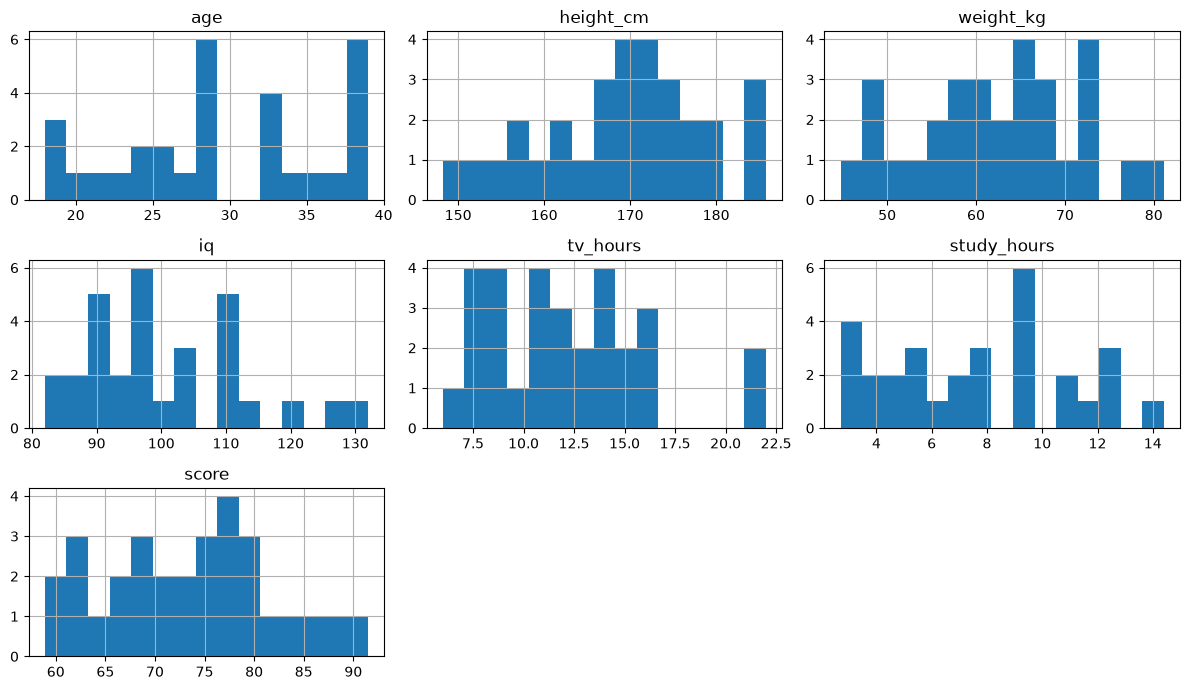

In [44]:
print(df.describe())
print(df.dtypes)
print(df.isna().sum())

columns = df.columns.drop('id')
df[columns].hist(figsize=(12, 7), bins=15)
plt.tight_layout()
plt.show()

**Вывод:** пропусков нет, все столбцы числовые, id убираем тк не показателен.
По гистограммам видно что симметрии много где нет, у height_cm небольшая асимметрия влево, у iq и tv_hours асимметрия вправо. Остальные распределения неровные, встречаются крайние значения.

### Задание 2. Связь height_cm и weight_kg

- Постройте scatter plot по признакам `height_cm` и `weight_kg`.
- Посчитайте коэффициент Пирсона и p-value.
- Интерпретируйте силу, направление и значимость связи в выводе.

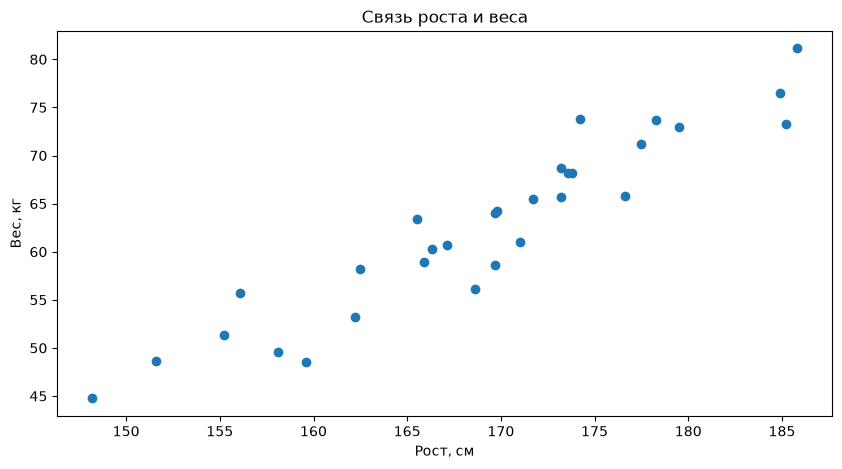

Пирсон r = 0.9435332044875275
p-value = 5.7989670932413515e-15


In [45]:
plt.figure(figsize=(10, 5))
plt.scatter(df['height_cm'], df['weight_kg'])
plt.xlabel('Рост, см')
plt.ylabel('Вес, кг')
plt.title('Связь роста и веса')
plt.show()

r, pvalue = stats.pearsonr(df['height_cm'], df['weight_kg'])
print(f'Пирсон r = {r}')
print(f'p-value = {pvalue}')

**Вывод:** коэффициент Пирсона r = 0.944 показывает сильную положительную связь между ростом и весом, чем выше рост - тем выше вес. p-value меньше 0.05, значит, связь статистически значимая.

### Задание 3. Связь tv_hours и iq

- Посчитайте ранговый коэффициент Спирмена между `tv_hours` и `iq` и p-value.
- Оцените, есть ли монотонная связь в выводе.

In [46]:
rho, pvalue = stats.spearmanr(df['tv_hours'], df['iq'])
print(f'Спирмен rho = {rho}')
print(f'p-value = {pvalue}')

Спирмен rho = -0.21078163442252332
p-value = 0.26354096475767624


**Вывод:** коэффициент Спирмена rho = -0.211 показывает слабую отрицательную связь между временем просмотра ТВ и IQ. Но p-value > 0.05, поэтому статистически значимой связи нет.

### Задание 4. Простая линейная регрессия weight_kg ~ height_cm

- Постройте регрессию, найдите intercept и slope, 95% доверительный интервал для наклона.
- Интерпретируйте результат в выводе.

In [47]:
x = sm.add_constant(df[['height_cm']])
y = df['weight_kg']
model = sm.OLS(y, x).fit()
print(f'intercept = {model.params["const"]}')
print(f'slope = {model.params["height_cm"]}')
dovdown, dovup = model.conf_int().loc['height_cm']
print(f'95% доверительного интервала наклона = ({dovdown}, {dovup})')

intercept = -90.49622681377843
slope = 0.9058658425123863
95% доверительного интервала наклона = (0.7827436005991039, 1.028988084425669)


**Вывод:** при увеличении роста на 1 см вес в среднем увеличивается на 0.906 кг.
95% доверительный интервал для наклона от 0.783 до 1.029 не включает 0, значит положительная связь статистически значимая.

### Задание 5. Прогноз и предсказательный интервал

- Для `height_cm = 175` вычислите точечный прогноз веса и 95% предсказательный интервал для нового наблюдения.

In [48]:
x0 = pd.DataFrame({'const': [1], 'height_cm': [175]})
pred = model.get_prediction(x0).summary_frame(alpha=0.05)
print(f'Прогноз веса = {pred["mean"].iloc[0]}')
print(f'95% предсказательный интервал = ({pred["obs_ci_lower"].iloc[0]}, {pred["obs_ci_upper"].iloc[0]})')


Прогноз веса = 68.03029562588918
95% предсказательный интервал = (61.53068736316749, 74.52990388861087)


**Вывод:** для человека ростом 175 см прогнозируемый вес = 68.03 кг. 95% предсказательный интервал для нового наблюдения от 61.53 до 74.53 кг

### Задание 6. Множественная регрессия

- Постройте модель score `~ study_hours + iq + tv_hours + age`.
- Выведите R^2 и оцените значимость предикторов по p-value.
- Дополнительно проверьте мультиколлинеарность через VIF.
- Запшите наблюдения в выводе.

In [49]:
formula_full = 'score ~ study_hours + iq + tv_hours + age'
model_full = smf.ols(formula_full, data=df).fit()
print(model_full.summary())

x = model_full.model.exog
vif = pd.DataFrame({
    'feature': model_full.model.exog_names,
    'VIF': [variance_inflation_factor(x, i) for i in range(x.shape[1])]
})
print(vif.round(1))

                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       0.874
Model:                            OLS   Adj. R-squared:                  0.854
Method:                 Least Squares   F-statistic:                     43.38
Date:                Sat, 28 Nov 2026   Prob (F-statistic):           6.73e-11
Time:                        17:20:02   Log-Likelihood:                -74.299
No. Observations:                  30   AIC:                             158.6
Df Residuals:                      25   BIC:                             165.6
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      45.6584      6.807      6.708      

**Вывод:** модель объясняет около 87.4% разброса score. При уровне 0.05 значимы study_hours и iq. VIF всех признаков около 1, поэтому сильной мультиколлинеарности не обнаружено.

### Задание 7. Ошибка модели

- Оцените типичную ошибку предсказаний модели из задания 6: вычислите RMSE (корень из средней квадратичной ошибки) на всей выборке и сравните её с разбросом целевой переменной (стандартным отклонением score).
- Насколько модель уменьшает типичную ошибку?

In [50]:
rmse = np.sqrt((model_full.resid**2).mean())
std = df["score"].std()
divide = 1 - rmse / std
print(f'RMSE: {rmse}')
print(f'Std score: {std}')
print(divide)

RMSE: 2.879693362024346
Std score: 8.253693008336455
0.6511024387367235


**Вывод:** Ошибка модели примерно на 65% меньше стандартного отклонениния исходных данных.

### Задание 8. Градиентный спуск

- Реализуйте градиентный спуск для простой регрессии score `~ study_hours` и сравните коэффициенты со `statsmodels`.
- Ответьте на вопрос: возможно ли получить метрику алгоритмом градиентного спуска лучше, чем у МНК?

In [51]:
x = df['study_hours'].to_numpy()
y = df['score'].to_numpy()
b0, b1, lr = 0.0, 0.0, 0.005
for _ in range(20000):
    err = (b0 + b1*x) - y
    b0 -= lr*err.mean()
    b1 -= lr*(err*x).mean()
print('Градиентный спуск:', b0, b1)
print('OLS:', sm.OLS(y, sm.add_constant(x)).fit().params)

Градиентный спуск: 56.03401079112716 2.273034892007336
OLS: [56.03402841  2.27303293]


**Вывод:** Градиентный спуск не может получить MSE ниже, чем МНК, на той же обучающей выборке, тк МНК ищет минимум суммы квадратов ошибок.

### Задание 9. Бутстрэп-интервал для корреляции

- Постройте бутстрэп-оценку 95% доверительного интервала для коэффициента Пирсона между `height_cm` и `weight_kg` (1000 бутстрэп-итераций, перцентильный метод).

In [52]:
np.random.seed(7)
height = df['height_cm'].values
weight = df['weight_kg'].values
n = len(df)
boots = []
for _ in range(1000):
    idx = np.random.randint(0, n, n)
    boots.append(stats.pearsonr(height[idx], weight[idx])[0])
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f'Бутстрэп 95% CI для корреляции: [{lo}, {hi}]')

Бутстрэп 95% CI для корреляции: [0.895612451265877, 0.9724827413437993]


**Вывод:** бутстрэп выше 0, значит есть положительная связь роста и веса

### Задание 10. Диагностика остатков

Для модели из задания 6 проведите диагностику остатков:
- постройте график остатков против предсказанных значений,
- QQ-plot остатков и гистограмму остатков.

Сделайте вывод о выполнении предпосылок регрессии.

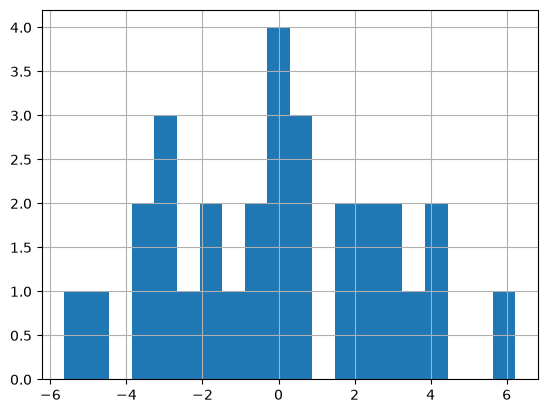

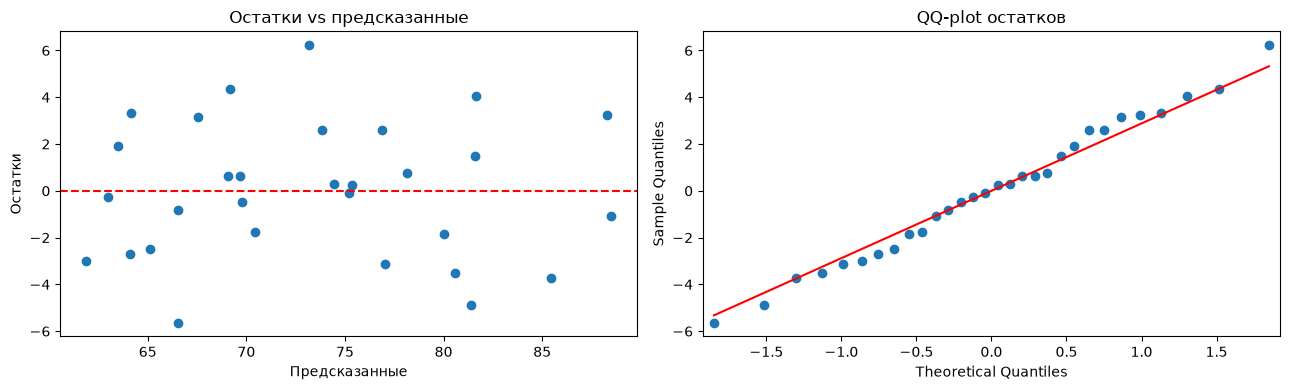

In [53]:
resid = model_full.resid
fitted = model_full.fittedvalues
resid.hist(bins=20)
plt.show()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].scatter(fitted, resid)
ax[0].axhline(0, color='red', ls='--')
ax[0].set_xlabel('Предсказанные')
ax[0].set_ylabel('Остатки')
ax[0].set_title('Остатки vs предсказанные')
sm.qqplot(resid, line='s', ax=ax[1])
ax[1].set_title('QQ-plot остатков')
plt.tight_layout()
plt.show()

**Вывод:** гистограмма околосимметрична, точки QQ-plot расположены близко к прямой. Графики выглядят нормально, проблем с моделью не видно.